In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import classification_report
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [2]:
iris = load_iris()

df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

df['target'] = iris.target

df = df[df['target'] != 2].copy()

print("First Five Records:")
display(df.head())

print("\nDataset Shape:", df.shape)

df.info()

First Five Records:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0



Dataset Shape: (100, 5)
<class 'pandas.core.frame.DataFrame'>
Index: 100 entries, 0 to 99
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  100 non-null    float64
 1   sepal width (cm)   100 non-null    float64
 2   petal length (cm)  100 non-null    float64
 3   petal width (cm)   100 non-null    float64
 4   target             100 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 4.7 KB


In [3]:
X = df[['petal length (cm)', 'petal width (cm)']]
y = df['target']

print("Input Features:")
display(X.head())

print("\nTarget Variable:")
print(y.head())

print("\nInput Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nClass Mapping:")
print("0 = Setosa")
print("1 = Versicolor")


Input Features:


,petal length (cm),petal width (cm)
0,1.4,0.2
1,1.4,0.2
2,1.3,0.2
3,1.5,0.2
4,1.4,0.2



Target Variable:
0    0
1    0
2    0
3    0
4    0
Name: target, dtype: int64

Input Shape: (100, 2)
Target Shape: (100,)

Class Mapping:
0 = Setosa
1 = Versicolor


In [4]:
print("Dataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())

print("\nClass Distribution:")
print(df['target'].value_counts().sort_index())

print("\nClass Names:")
print("0 = Setosa")
print("1 = Versicolor")

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
Index: 100 entries, 0 to 99
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  100 non-null    float64
 1   sepal width (cm)   100 non-null    float64
 2   petal length (cm)  100 non-null    float64
 3   petal width (cm)   100 non-null    float64
 4   target             100 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 4.7 KB

Statistical Summary:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,100.000000,100.000000,100.000000,100.000000,100.000000
mean,5.471000,3.099000,2.861000,0.786000,0.500000
std,0.641698,0.478739,1.449549,0.565153,0.502519
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.000000,2.800000,1.500000,0.200000,0.000000
50%,5.400000,3.050000,2.450000,0.800000,0.500000
75%,5.900000,3.400000,4.325000,1.300000,1.000000
max,7.000000,4.400000,5.100000,1.800000,1.000000



Missing Values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
dtype: int64

Duplicate Records: 0

Class Distribution:
target
0    50
1    50
Name: count, dtype: int64

Class Names:
0 = Setosa
1 = Versicolor


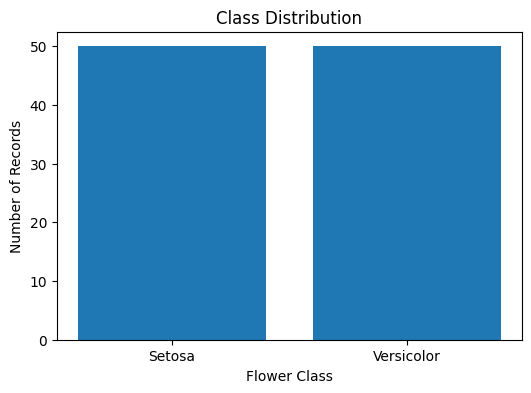

In [5]:
class_counts = df['target'].value_counts().sort_index()

plt.figure(figsize=(6, 4))
plt.bar(['Setosa', 'Versicolor'], class_counts.values)

plt.title("Class Distribution")
plt.xlabel("Flower Class")
plt.ylabel("Number of Records")
plt.show()

In [7]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)



In [8]:
print("Training Data Shape:", X_train_scaled.shape)
print("Testing Data Shape:", X_test_scaled.shape)

print("\nTraining Class Distribution:")
print(y_train.value_counts())

print("\nTesting Class Distribution:")
print(y_test.value_counts())

Training Data Shape: (80, 2)
Testing Data Shape: (20, 2)

Training Class Distribution:
target
0    40
1    40
Name: count, dtype: int64

Testing Class Distribution:
target
1    10
0    10
Name: count, dtype: int64


In [9]:
#sigmoid function
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

z = np.linspace(-10, 10, 100)

y_sigmoid = sigmoid(z)

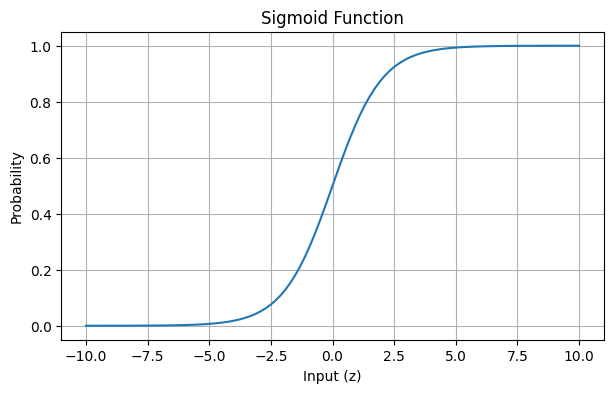

In [10]:
plt.figure(figsize=(7, 4))
plt.plot(z, y_sigmoid)

plt.title("Sigmoid Function")
plt.xlabel("Input (z)")
plt.ylabel("Probability")
plt.grid()
plt.show()

In [12]:
model = LogisticRegression(random_state=42)

model.fit(X_train_scaled, y_train)

print("Model Intercept:")
print(model.intercept_)

print("\nModel Coefficients:")

for feature, coef in zip(X.columns, model.coef_[0]):
    print(feature, ":", coef)

Model Intercept:
[0.24373421]

Model Coefficients:
petal length (cm) : 2.0120066009598743
petal width (cm) : 1.9108760089814074


In [13]:
#logistic regression model
model = LogisticRegression(random_state=42)

model.fit(X_train_scaled, y_train)

print("Model Intercept:")
print(model.intercept_)

print("\nModel Coefficients:")

for feature, coef in zip(X.columns, model.coef_[0]):
    print(feature, ":", coef)

Model Intercept:
[0.24373421]

Model Coefficients:
petal length (cm) : 2.0120066009598743
petal width (cm) : 1.9108760089814074


In [14]:
# creating logistic regression model
model = LogisticRegression(random_state=42)

model.fit(X_train_scaled, y_train)

print("Intercept:", model.intercept_)

print("\nCoefficients:")

for feature, coef in zip(X.columns, model.coef_[0]):
    print(feature, ":", coef)

Intercept: [0.24373421]

Coefficients:
petal length (cm) : 2.0120066009598743
petal width (cm) : 1.9108760089814074


In [16]:
# predict flower classes
y_pred = model.predict(X_test_scaled)

y_prob = model.predict_proba(X_test_scaled)

results = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred,
    'Probability of Setosa': y_prob[:, 0],
    'Probability of Versicolor': y_prob[:, 1]
})

print("Prediction Results:")
display(results.head(10))

Prediction Results:


,Actual,Predicted,Probability of Setosa,Probability of Versicolor
0,1,1,0.169350,0.830650
1,1,1,0.001655,0.998345
2,1,1,0.007070,0.992930
3,1,1,0.006643,0.993357
4,0,0,0.976061,0.023939
5,0,0,0.984192,0.015808
6,0,0,0.968502,0.031498
7,1,1,0.010755,0.989245
8,0,0,0.956103,0.043897
9,0,0,0.988032,0.011968


Confusion Matrix:
[[10  0]
 [ 0 10]]


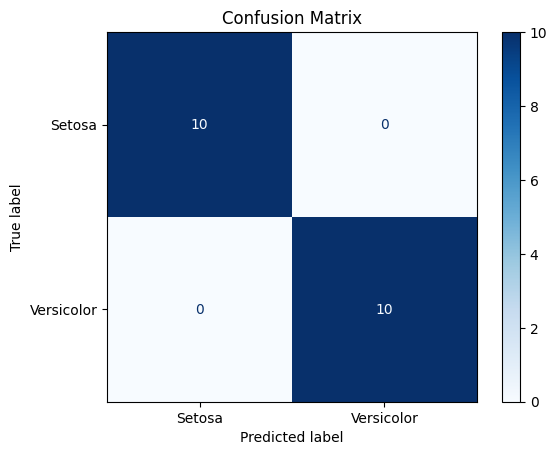

In [18]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Setosa', 'Versicolor']
)

disp.plot(cmap='Blues')
plt.title("Confusion Matrix")
plt.show()

In [20]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Model Evaluation Results")

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=['Setosa', 'Versicolor']
))

Model Evaluation Results
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0

Classification Report:
              precision    recall  f1-score   support

      Setosa       1.00      1.00      1.00        10
  Versicolor       1.00      1.00      1.00        10

    accuracy                           1.00        20
   macro avg       1.00      1.00      1.00        20
weighted avg       1.00      1.00      1.00        20



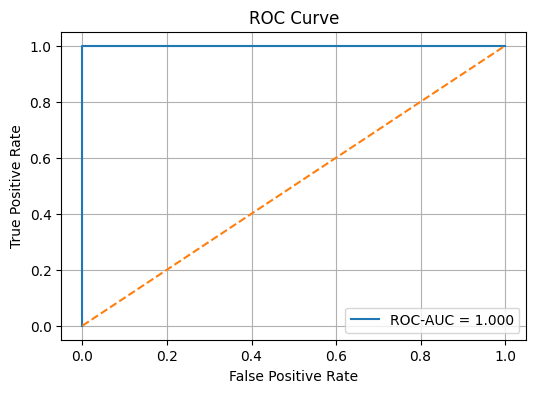

ROC-AUC Score: 1.0


In [23]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob[:, 1])

roc_auc = roc_auc_score(y_test, y_prob[:, 1])

plt.figure(figsize=(6, 4))

plt.plot(fpr, tpr, label=f'ROC-AUC = {roc_auc:.3f}')
plt.plot([0, 1], [0, 1], linestyle='--')

plt.title("ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid()
plt.show()

print("ROC-AUC Score:", roc_auc)

In [26]:
baseline = DummyClassifier(strategy='most_frequent')

baseline.fit(X_train_scaled, y_train)

baseline_pred = baseline.predict(X_test_scaled)

baseline_accuracy = accuracy_score(y_test, baseline_pred)

print("Baseline Accuracy:", baseline_accuracy)
print("Logistic Regression Accuracy:", accuracy)

Baseline Accuracy: 0.5
Logistic Regression Accuracy: 1.0


In [28]:

thresholds = [0.3, 0.5, 0.7]

print("Threshold Comparison:\n")

for threshold in thresholds:

    predictions = (y_prob[:, 1] >= threshold).astype(int)

    print("Threshold:", threshold)
    print("Accuracy:", accuracy_score(y_test, predictions))
    print("Precision:", precision_score(y_test, predictions, zero_division=0))
    print("Recall:", recall_score(y_test, predictions, zero_division=0))
    print("F1 Score:", f1_score(y_test, predictions, zero_division=0))
    print("-------------------------")

Threshold Comparison:

Threshold: 0.3
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0
-------------------------
Threshold: 0.5
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0
-------------------------
Threshold: 0.7
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0
-------------------------


In [29]:
# Testing new flower measurements
new_flower = pd.DataFrame({
    'petal length (cm)': [4.5],
    'petal width (cm)': [1.5]
})

new_flower_scaled = scaler.transform(new_flower)

prediction = model.predict(new_flower_scaled)
probability = model.predict_proba(new_flower_scaled)

print("Predicted Class:", prediction[0])
print("Probability of Setosa:", probability[0][0])
print("Probability of Versicolor:", probability[0][1])

if prediction[0] == 0:
    print("Flower Type: Setosa")
else:
    print("Flower Type: Versicolor")

Predicted Class: 1
Probability of Setosa: 0.006643380808203259
Probability of Versicolor: 0.9933566191917967
Flower Type: Versicolor
